# Mount Drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Dowaload Data set

In [ ]:
import kagglehub
import os
import shutil

source_path = kagglehub.dataset_download("mathewribeiro/spiderscorpioncochroach")

target_drive_path = "/content/drive/MyDrive/SVM"

os.makedirs(target_drive_path, exist_ok=True)

print(f"Dataset downloaded temporarily to: {source_path}")
print(f"Copying contents to: {target_drive_path}...")

for item_name in os.listdir(source_path):
    source_item_path = os.path.join(source_path, item_name)
    target_item_path = os.path.join(target_drive_path, item_name)
    if os.path.isdir(source_item_path):
        shutil.copytree(source_item_path, target_item_path, dirs_exist_ok=True)
    else:
        shutil.copy2(source_item_path, target_item_path)

print(f"Successfully copied dataset contents to: {target_drive_path}")


100%|██████████| 89.7M/89.7M [00:00<00:00, 271MB/s]

Extracting files...


Dataset downloaded temporarily to: /root/.cache/kagglehub/datasets/mathewribeiro/spiderscorpioncochroach/versions/1
Copying contents to: /content/drive/MyDrive/SVM...
Successfully copied dataset contents to: /content/drive/MyDrive/SVM


# Data check

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
def count_files_in_subfolders(directory):
    total_files = 0
    folder_file_counts = {}

    for root, dirs, files in os.walk(directory):
        if root == directory:
            continue
        folder_name = os.path.basename(root)
        file_count = len(files)
        total_files += file_count
        folder_file_counts[folder_name] = file_count

    print(f"Total files: {total_files}\n")
    accumulated_ratio = 0
    for folder_name, file_count in folder_file_counts.items():
        if file_count > 0:
            ratio = file_count / total_files if total_files > 0 else 0
            print(f"Folder: {folder_name} - File count: {file_count} - Ratio: {ratio:.2%}")
            accumulated_ratio += ratio
    print(f"Sum of ratios (as float): {accumulated_ratio:.2f}")

In [ ]:
def plot_file_count_in_subfolders(root_dir):
    subfolder_counts = []

    for subfolder in os.listdir(root_dir):
        subfolder_path = os.path.join(root_dir, subfolder)
        if os.path.isdir(subfolder_path):
            file_count = len(os.listdir(subfolder_path))
            subfolder_counts.append({'Subfolder': subfolder, 'FileCount': file_count})

    df = pd.DataFrame(subfolder_counts)

    if df.empty:
        print("DataFrame is empty. No files found in subfolders.")
        return

    print(df)

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')

    plt.xticks(rotation=45, ha='right')
    plt.title('File Count in Subfolders')
    plt.ylabel('Number of Files')
    plt.xlabel('Subfolder')
    plt.tight_layout()
    plt.show()

In [ ]:
count_files_in_subfolders('/content/drive/MyDrive/SVM/train')

Total files: 998

Folder: scorpions - File count: 367 - Ratio: 36.77%
Folder: cockroaches - File count: 303 - Ratio: 30.36%
Folder: spiders - File count: 328 - Ratio: 32.87%
Sum of ratios (as float): 1.00


     Subfolder  FileCount
0    scorpions        367
1  cockroaches        303
2      spiders        328


/tmp/ipython-input-2887820571.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


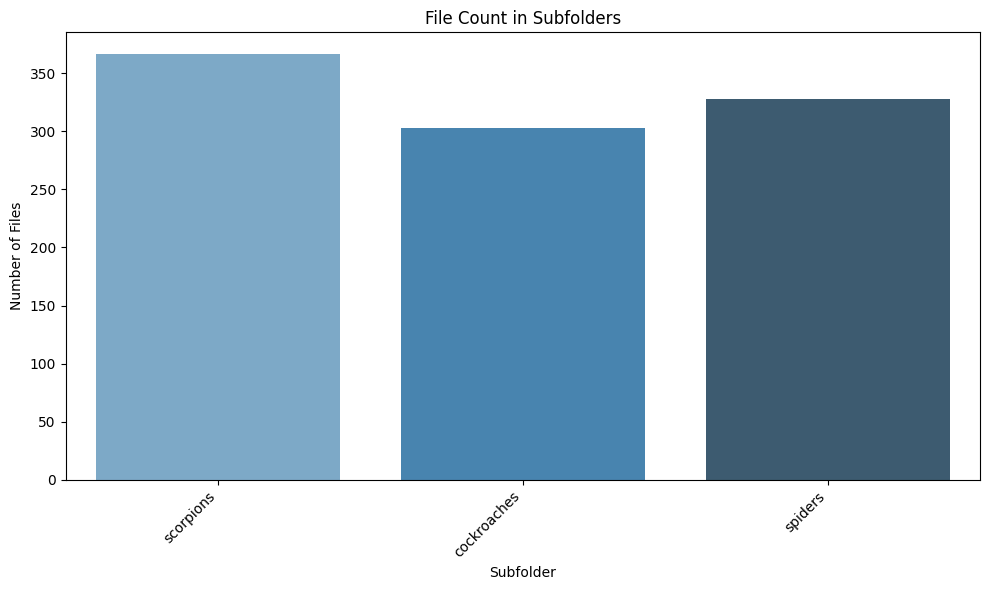

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/SVM/train')

# Imbalanced Data with Random

In [ ]:
import os
import random
import shutil

def random_file_picker_and_copier(root_path, output_path, n_files=1, seed=None):
    """
    Randomly pick n files from each class directory in the root_path and copy them to the output_path.

    Args:
        root_path (str): Path to the root directory containing class subdirectories.
        output_path (str): Path to the output directory where files will be copied.
        n_files (int): Number of files to pick from each class.
        seed (int, optional): Seed for random number generator. If None, uses system time.

    Returns:
        dict: A dictionary where keys are class names and values are lists of copied file paths.
    """
    # Set the random seed
    random.seed(seed)

    copied_files = {}

    # Iterate over each class directory in the root path
    for class_name in os.listdir(root_path):
        class_path = os.path.join(root_path, class_name)

        # Skip if it's not a directory
        if not os.path.isdir(class_path):
            continue

        # Get all files in the current class directory
        all_files = [
            os.path.join(class_path, f)
            for f in os.listdir(class_path)
            if os.path.isfile(os.path.join(class_path, f))
        ]

        # Randomly select n files (or fewer if not enough files are available)
        selected_files = random.sample(all_files, min(n_files, len(all_files)))

        # Create output directory for the current class
        class_output_path = os.path.join(output_path, class_name)
        os.makedirs(class_output_path, exist_ok=True)

        # Copy the selected files to the output directory
        copied = []
        for file_path in selected_files:
            file_name = os.path.basename(file_path)
            dest_path = os.path.join(class_output_path, file_name)
            shutil.copy2(file_path, dest_path)
            copied.append(dest_path)

        # Store the copied files for the current class
        copied_files[class_name] = copied

    return copied_files

In [ ]:
# Example usage
root_path = "/content/drive/MyDrive/SVM/train"  # Replace with your dataset path
output_path = "/content/drive/MyDrive/SVM/Data"  # Replace with your desired output path
n_files_to_pick = 300 # Adjust to the number of files you want to pick from each class
seed_value = 54  # Optional seed for reproducibility

copied_files = random_file_picker_and_copier(root_path, output_path, n_files_to_pick, seed=seed_value)

# Print summary
for class_name, files in copied_files.items():
    print(f"Class: {class_name} - Files copied: {len(files)}")


Class: scorpions - Files copied: 300
Class: cockroaches - Files copied: 300
Class: spiders - Files copied: 300
Class: .ipynb_checkpoints - Files copied: 0


# Check image dimensions

In [ ]:
import os
from PIL import Image
from collections import Counter

def check_image_sizes(input_dir: str):
    # เก็บข้อมูลขนาดของภาพในแต่ละคลาส
    class_sizes = {}

    for class_name in os.listdir(input_dir):
        class_dir = os.path.join(input_dir, class_name)
        if os.path.isdir(class_dir):
            class_sizes[class_name] = []

            # ตรวจสอบไฟล์ภาพในโฟลเดอร์
            for image_file in os.listdir(class_dir):
                if image_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
                    image_path = os.path.join(class_dir, image_file)
                    try:
                        with Image.open(image_path) as img:
                            # เก็บขนาดของภาพ
                            class_sizes[class_name].append(img.size)
                    except Exception as e:
                        print(f"Error loading {image_file}: {e}")

    # สรุปขนาดภาพในแต่ละคลาส
    for class_name, sizes in class_sizes.items():
        print(f"Class: {class_name}")
        size_counts = Counter(sizes)
        for size, count in size_counts.items():
            print(f"  Size: {size[0]}x{size[1]}, Count: {count}")

# ตัวอย่างการใช้งาน
input_dir = '/content/drive/MyDrive/SVM/Data'
check_image_sizes(input_dir)


Class: scorpions
  Size: 365x365, Count: 2
  Size: 620x620, Count: 1
  Size: 720x720, Count: 1
  Size: 254x254, Count: 1
  Size: 152x152, Count: 1
  Size: 348x348, Count: 1
  Size: 530x530, Count: 2
  Size: 53x53, Count: 1
  Size: 613x613, Count: 1
  Size: 139x139, Count: 1
  Size: 245x245, Count: 3
  Size: 571x571, Count: 3
  Size: 595x595, Count: 2
  Size: 695x695, Count: 2
  Size: 90x90, Count: 3
  Size: 605x605, Count: 1
  Size: 71x71, Count: 1
  Size: 16x16, Count: 1
  Size: 375x375, Count: 1
  Size: 611x611, Count: 1
  Size: 424x424, Count: 2
  Size: 62x62, Count: 1
  Size: 354x354, Count: 1
  Size: 96x96, Count: 1
  Size: 157x157, Count: 1
  Size: 214x214, Count: 1
  Size: 691x691, Count: 2
  Size: 402x402, Count: 1
  Size: 30x30, Count: 2
  Size: 711x711, Count: 2
  Size: 649x649, Count: 1
  Size: 264x264, Count: 2
  Size: 137x137, Count: 1
  Size: 441x441, Count: 1
  Size: 65x65, Count: 1
  Size: 475x475, Count: 1
  Size: 399x399, Count: 1
  Size: 208x208, Count: 1
  Size: 98x

# Augment picture

In [ ]:
import os
import cv2
import numpy as np
import albumentations as A
from tqdm import tqdm

class WoundImagePreprocessor:
    def __init__(self, input_dir, output_dir, resize_dim=(224, 224),
                 class_names=['scorpions', 'spiders']):
        self.input_dir = input_dir
        self.output_dir = output_dir
        self.resize_dim = resize_dim
        self.class_names = class_names

        # Create output directory
        os.makedirs(output_dir, exist_ok=True)

    def _resize_image(self, image):
        """Resize image to target dimensions"""
        return cv2.resize(image, self.resize_dim, interpolation=cv2.INTER_LANCZOS4)

    def _create_augmentations(self):
        """Create augmentation transformations"""
        return {
            'brightness_contrast': A.Compose([
                A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'medical_noise': A.Compose([
                A.GaussNoise(var_limit=(10.0, 30.0), p=0.3),
                A.MedianBlur(blur_limit=3, p=0.2),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'color_jitter': A.Compose([
                A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.1, p=0.5),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'geometric_transforms': A.Compose([
                A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=20, p=0.5),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'rotate': A.Compose([
                A.Rotate(limit=40, p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'affine_shear': A.Compose([
                A.Affine(shear=15, p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'random_scale': A.Compose([
                A.RandomScale(scale_limit=0.3, p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'horizontal_flip': A.Compose([
                A.HorizontalFlip(p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ]),
            'vertical_flip': A.Compose([
                A.VerticalFlip(p=1.0),
                A.Resize(height=self.resize_dim[0], width=self.resize_dim[1], interpolation=cv2.INTER_LANCZOS4)
            ])
        }

    def preprocess_and_augment(self):
        """Process and augment images for each class"""
        augmentations = self._create_augmentations()

        for class_name in self.class_names:
            # Input directory for the current class
            class_input_dir = os.path.join(self.input_dir, class_name)
            class_output_dir = os.path.join(self.output_dir, class_name)

            # Create output directory for this class
            os.makedirs(class_output_dir, exist_ok=True)

            # Process each image in the class
            for image_file in tqdm(os.listdir(class_input_dir), desc=f"Processing {class_name}"):
                if image_file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
                    # Read and convert image
                    image_path = os.path.join(class_input_dir, image_file)
                    image = cv2.imread(image_path)
                    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

                    # Resize image
                    resized_image = self._resize_image(image)

                    # Save resized image
                    resized_output_path = os.path.join(class_output_dir, f"resized_{image_file}")
                    cv2.imwrite(resized_output_path, cv2.cvtColor(resized_image, cv2.COLOR_RGB2BGR))

                    # Perform augmentations
                    for aug_name, aug_transform in augmentations.items():
                        augmented_image = aug_transform(image=resized_image)['image']
                        aug_output_filename = f"aug_{aug_name}_{image_file}"
                        aug_output_path = os.path.join(class_output_dir, aug_output_filename)
                        cv2.imwrite(aug_output_path, cv2.cvtColor(augmented_image, cv2.COLOR_RGB2BGR))

def main():
    # Directories for input and output
    input_dir = '/content/drive/MyDrive/SVM/Data'
    output_dir = '/content/drive/MyDrive/SVM/Data224'

    # Initialize and run preprocessing
    preprocessor = WoundImagePreprocessor(input_dir=input_dir, output_dir=output_dir)
    preprocessor.preprocess_and_augment()

if __name__ == "__main__":
    main()

/tmp/ipython-input-1982313254.py:30: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 30.0), p=0.3),
Processing spiders: 100%|██████████| 300/300 [00:43<00:00,  6.83it/s]


In [ ]:
count_files_in_subfolders('/content/drive/MyDrive/SVM/Data224')

Total files: 6000

Folder: scorpions - File count: 3000 - Ratio: 50.00%
Folder: spiders - File count: 3000 - Ratio: 50.00%
Sum of ratios (as float): 1.00


# Splitfolders

In [ ]:
!pip install -q split-folders

In [ ]:
import splitfolders
splitfolders.ratio("/content/drive/MyDrive/SVM/Data224",
                    output="/content/drive/MyDrive/SVM/Datasplit",
                    seed=69,
                    ratio=(0.7,0.2,0.1),
                    move=False)

Copying files: 6000 files [02:07, 47.19 files/s]


   Subfolder  FileCount
0  scorpions       2100
1    spiders       2100


/tmp/ipython-input-648414440.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


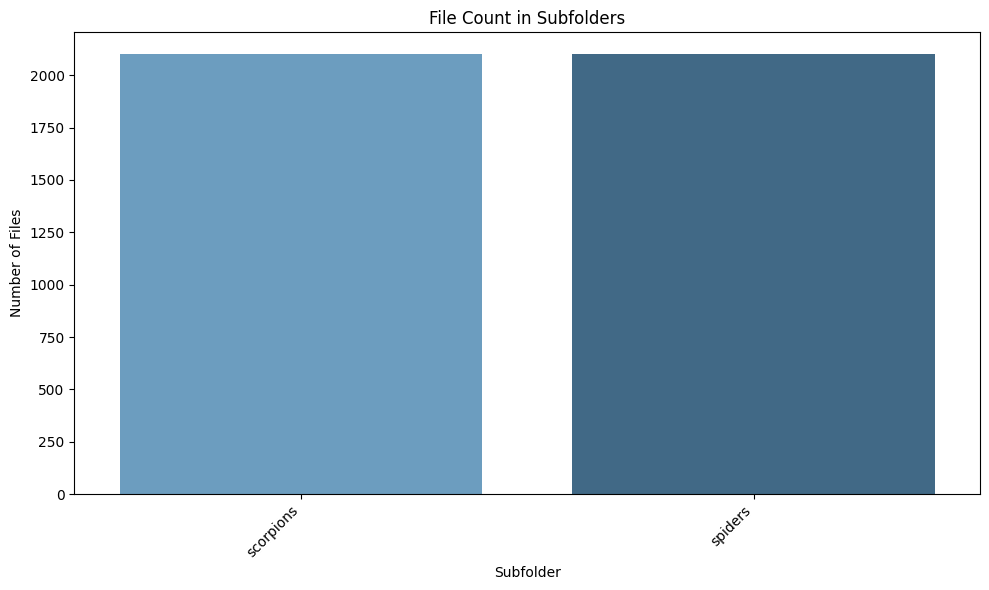

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/SVM/Datasplit/train')

   Subfolder  FileCount
0  scorpions        300
1    spiders        300


/tmp/ipython-input-648414440.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


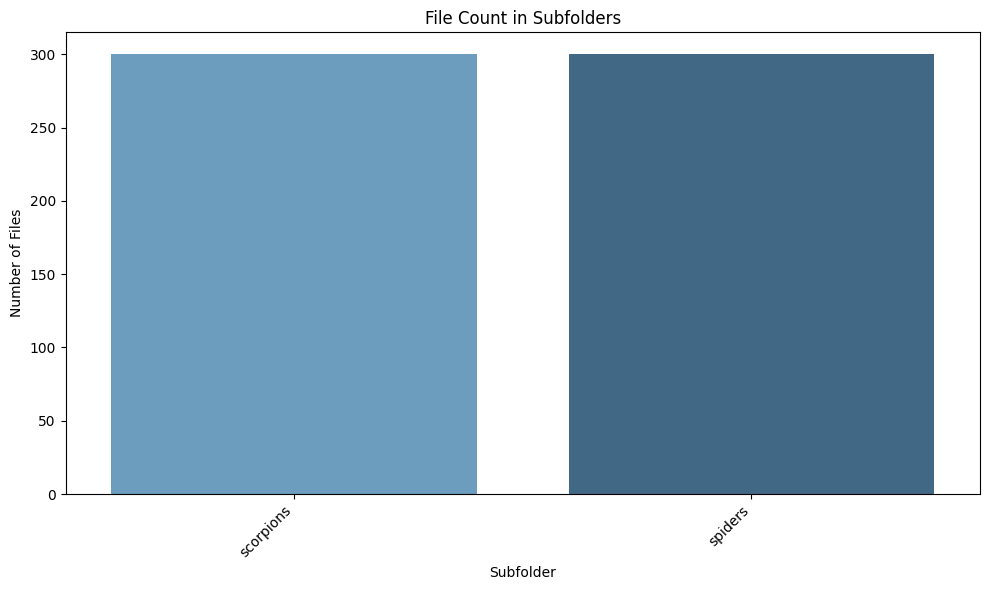

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/SVM/Datasplit/test')

   Subfolder  FileCount
0  scorpions        600
1    spiders        600


/tmp/ipython-input-648414440.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Subfolder', y='FileCount', data=df, palette='Blues_d')


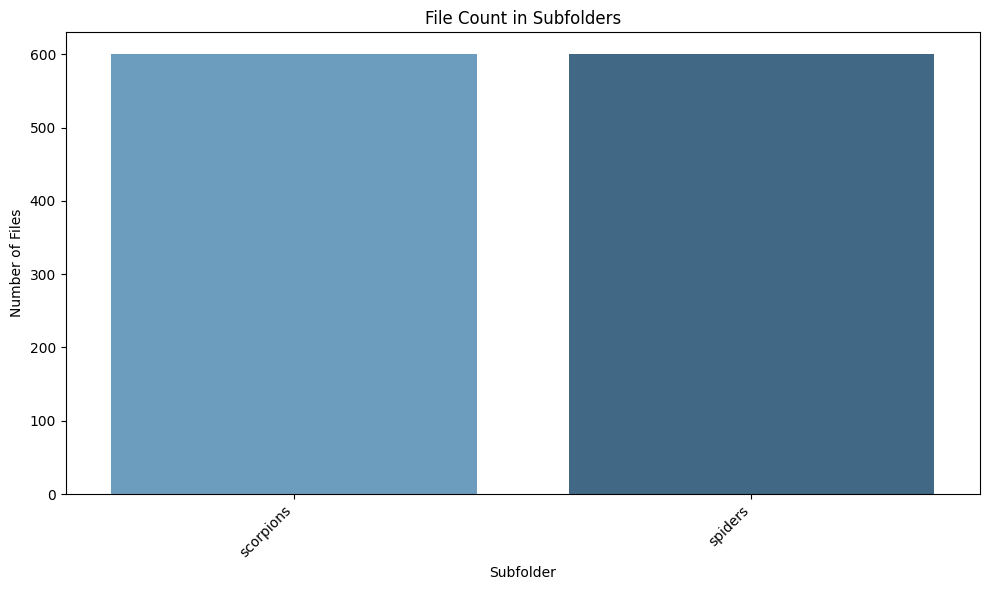

In [ ]:
plot_file_count_in_subfolders('/content/drive/MyDrive/SVM/Datasplit/val')

# Check image dimensions

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
from collections import Counter

def get_image_dimensions(root_dir):
    image_dimensions = []
    for subdir, dirs, files in os.walk(root_dir):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif')):
                file_path = os.path.join(subdir, file)
                image = cv2.imread(file_path)
                if image is not None:
                    dimensions = image.shape
                    image_dimensions.append(dimensions)
                else:
                    print(f"Error: Unable to read image at {file_path}")
    return image_dimensions

def plot_dimensions(dimensions):
    # Count the occurrences of each dimension
    dimension_counts = Counter(dimensions)
    # Separate the dimensions and their counts
    dims, counts = zip(*dimension_counts.items())
    # Create a bar chart
    plt.bar(range(len(dims)), counts, tick_label=[f"{d[0]}x{d[1]}" for d in dims])
    plt.xlabel('Image Dimensions')
    plt.ylabel('Frequency')
    plt.title('Distribution of Image Dimensions')
    plt.xticks(rotation=90)
    plt.show()

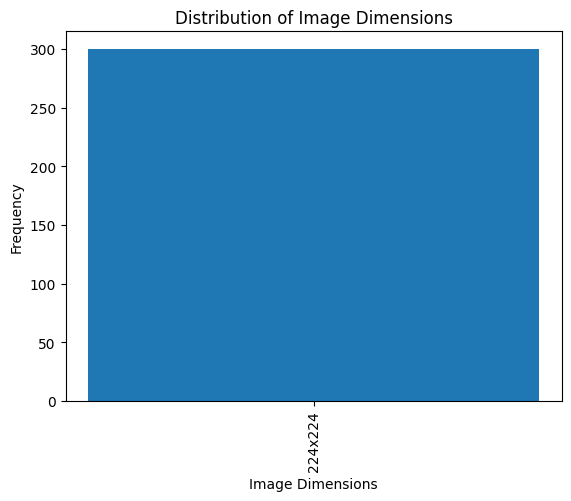

In [ ]:
shape_dict = get_image_dimensions('/content/drive/MyDrive/SVM/Datasplit/test/scorpions')
plot_dimensions(shape_dict)

#Plot data

Loaded: (4200, 4096) labels: (4200,)
PCA shape: (4200, 2)


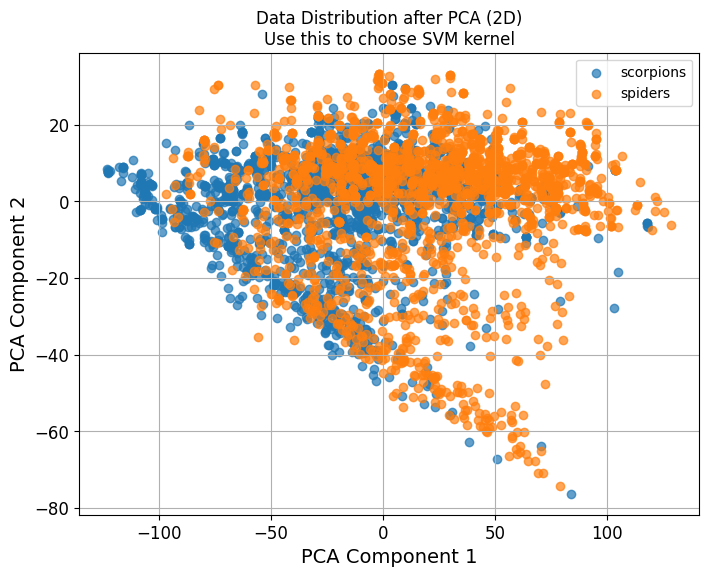

In [ ]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# -----------------------------
# 1) โหลดข้อมูล + แปลงรูปเป็นเวกเตอร์
# -----------------------------
data_dir = "/content/drive/MyDrive/SVM/Datasplit/train"

classes = ["scorpions", "spiders"]
X = []
y = []

img_size = (64, 64)   # ปรับได้ตามต้องการ

for label, cls in enumerate(classes):
    cls_path = os.path.join(data_dir, cls)
    for fname in os.listdir(cls_path):
        fpath = os.path.join(cls_path, fname)

        try:
            img = Image.open(fpath).convert("L").resize(img_size)
            arr = np.array(img, dtype=np.float32).flatten() / 255.0

            X.append(arr)
            y.append(label)
        except:
            pass

X = np.array(X)
y = np.array(y)

print("Loaded:", X.shape, "labels:", y.shape)

# -----------------------------
# 2) Normalize ก่อนทำ PCA
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -----------------------------
# 3) ลดมิติเป็น 2D ด้วย PCA
# -----------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("PCA shape:", X_pca.shape)

# -----------------------------
# 4) Plot การกระจายตัวของข้อมูล
# -----------------------------
plt.figure(figsize=(8,6))
for label, cls in enumerate(classes):
    plt.scatter(
        X_pca[y == label, 0],
        X_pca[y == label, 1],
        label=cls,
        alpha=0.7
    )

plt.title("Data Distribution after PCA (2D)\nUse this to choose SVM kernel")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.grid(True)
plt.show()


## Linear model


# Train Nomal Model


In [ ]:
import numpy as np
from PIL import Image

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_recall_fscore_support,
    classification_report
)

import matplotlib.pyplot as plt


In [ ]:
base_dir = "/content/drive/MyDrive/SVM/Datasplit"

train_dir = os.path.join(base_dir, "train")
val_dir   = os.path.join(base_dir, "val")
test_dir  = os.path.join(base_dir, "test")

classes = ["scorpions", "spiders"]
IMG_SIZE = 64


In [ ]:
def load_dataset(split_dir, classes, img_size=64):
    X = []
    y = []
    for label_id, cls in enumerate(classes):
        folder = os.path.join(split_dir, cls)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            try:
                img = Image.open(fpath).convert("L")  # แปลงเป็น grayscale
                img = img.resize((img_size, img_size))
                arr = np.array(img, dtype=np.float32) / 255.0  # normalize 0-1
                X.append(arr.flatten())  # แปลงเป็นเวกเตอร์ 1 มิติ
                y.append(label_id)       # 0 = scorpions, 1 = spiders
            except Exception as e:
                print("โหลดรูปไม่ได้:", fpath, e)
    return np.array(X), np.array(y)

X_train, y_train = load_dataset(train_dir, classes, IMG_SIZE)
X_val,   y_val   = load_dataset(val_dir,   classes, IMG_SIZE)
X_test,  y_test  = load_dataset(test_dir,  classes, IMG_SIZE)

X_train.shape, X_val.shape, X_test.shape


((4200, 4096), (1200, 4096), (600, 4096))

In [ ]:
# รวม train + val
X_train_all = np.concatenate([X_train, X_val], axis=0)
y_train_all = np.concatenate([y_train, y_val], axis=0)

# Standardize: ทำให้แต่ละ feature มี mean=0, std=1
scaler = StandardScaler()
X_train_all_scaled = scaler.fit_transform(X_train_all)
X_test_scaled      = scaler.transform(X_test)


In [ ]:
# พารามิเตอร์ที่ใช้
C_value = 1.0      # regularization (soft margin) ยิ่งใหญ่ยิ่งบีบให้ผิดน้อย
kernel_type = "linear"  # ใช้ linear kernel เพื่อให้วาดเส้นง่าย

svm_clf = SVC(
    kernel=kernel_type,
    C=C_value,
    gamma="scale",   # สำหรับ linear ไม่ค่อยมีผล แต่ sklearn บังคับระบุ
    probability=False
)

svm_clf.fit(X_train_all_scaled, y_train_all)


SVC(kernel='linear')

# Evaluate


In [ ]:
y_pred = svm_clf.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average=None, labels=[0, 1]
)

print("Accuracy:", acc)
print()
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=classes))


Accuracy: 0.8066666666666666

Classification report:
              precision    recall  f1-score   support

   scorpions       0.82      0.79      0.80       300
     spiders       0.80      0.82      0.81       300

    accuracy                           0.81       600
   macro avg       0.81      0.81      0.81       600
weighted avg       0.81      0.81      0.81       600



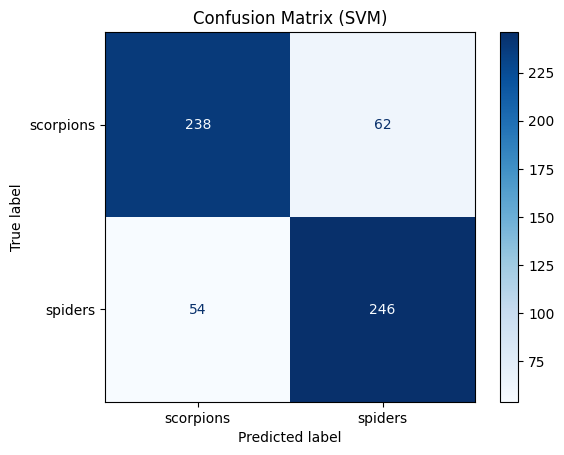

In [ ]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0,1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix (SVM)")
plt.show()


# Plot SVM

In [ ]:
# PCA ลดมิติจาก 4096 → 2 เพื่อใช้ visualize
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_all_scaled)
X_test_pca  = pca.transform(X_test_scaled)

# เทรน SVM ใหม่บน space 2D นี้ (เพื่อให้เส้นแบ่งในกราฟตรงกับ classifier)
svm_2d = SVC(kernel="linear", C=C_value)
svm_2d.fit(X_train_pca, y_train_all)


SVC(kernel='linear')

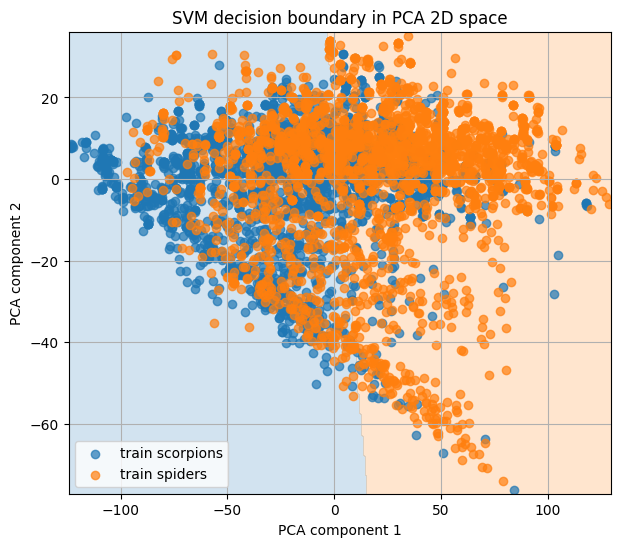

In [ ]:
# วาด decision boundary + จุดข้อมูล
plt.figure(figsize=(7,6))

# สร้าง grid 2D เพื่อเอาไปผ่าน SVM แล้ววาดเส้น
x_min, x_max = X_train_pca[:,0].min() - 1, X_train_pca[:,0].max() + 1
y_min, y_max = X_train_pca[:,1].min() - 1, X_train_pca[:,1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = svm_2d.predict(grid_points)
Z = Z.reshape(xx.shape)

# พื้นหลังสีแบ่งโซนของแต่ละคลาส
plt.contourf(xx, yy, Z, alpha=0.2, levels=[-0.5,0.5,1.5], colors=["tab:blue","tab:orange"])

# วาดจุด train
for label_id, cls in enumerate(classes):
    idx = (y_train_all == label_id)
    plt.scatter(
        X_train_pca[idx, 0],
        X_train_pca[idx, 1],
        label=f"train {cls}",
        alpha=0.7
    )

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("SVM decision boundary in PCA 2D space")
plt.legend()
plt.grid(True)
plt.show()


## Not-Linear model


# Train model

In [ ]:
# ★ แก้ path ให้ตรงกับของคุณ
base_dir = "/content/drive/MyDrive/SVM/Datasplit"

train_dir = os.path.join(base_dir, "train")
val_dir   = os.path.join(base_dir, "val")
test_dir  = os.path.join(base_dir, "test")

classes = ["scorpions", "spiders"]   # 2 คลาส
IMG_SIZE = 64                        # ย่อรูปให้เล็กลงเพื่อเทรนไว


In [ ]:
def load_dataset(split_dir, classes, img_size=64):
    X, y = [], []
    for label_id, cls in enumerate(classes):
        folder = os.path.join(split_dir, cls)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            try:
                img = Image.open(fpath).convert("L")          # แปลงเป็น grayscale
                img = img.resize((img_size, img_size))       # resize
                arr = np.array(img, dtype=np.float32) / 255.0
                X.append(arr.flatten())                      # flatten เป็นเวกเตอร์ 1D
                y.append(label_id)                           # 0 = scorpions, 1 = spiders
            except Exception as e:
                print("โหลดรูปไม่ได้:", fpath, "=>", e)
    return np.array(X), np.array(y)

X_train, y_train = load_dataset(train_dir, classes, IMG_SIZE)
X_val,   y_val   = load_dataset(val_dir,   classes, IMG_SIZE)
X_test,  y_test  = load_dataset(test_dir,  classes, IMG_SIZE)

X_train.shape, X_val.shape, X_test.shape


((4200, 4096), (1200, 4096), (600, 4096))

In [ ]:
# รวม train + val เป็นชุดฝึกเดียว
X_train_all = np.concatenate([X_train, X_val], axis=0)
y_train_all = np.concatenate([y_train, y_val], axis=0)

# Standardize: ให้แต่ละ feature มี mean=0, std=1 (สำคัญมากสำหรับ SVM)
scaler = StandardScaler()
X_train_all_scaled = scaler.fit_transform(X_train_all)
X_test_scaled      = scaler.transform(X_test)


In [ ]:
# ★ พารามิเตอร์ SVM (ปรับได้)
C_value    = 5.0        # ควบคุม soft margin (ยิ่งมาก → ยิ่งพยายามทายถูกทุกจุด)
gamma_value = "scale"   # สำหรับ RBF kernel: 'scale' = 1 / (n_features * var)

svm_rbf = SVC(
    kernel="rbf",       # ★ Nonlinear SVM: RBF kernel
    C=C_value,
    gamma=gamma_value,
    probability=False
)

svm_rbf.fit(X_train_all_scaled, y_train_all)


SVC(C=5.0)

ใน sklearn มีสมการสำหรับการหาค่าแกรมมาที่เหมาะสมกับข้อมูลที่ใช้โดยใช้สมการตามนี้
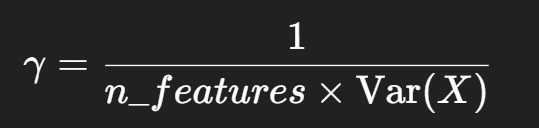

# Evaluate

In [ ]:
y_pred = svm_rbf.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)

print("=== Metrics (RBF SVM) ===")
print("Accuracy:", acc)
print()
print("Classification report:")
print(classification_report(y_test, y_pred, target_names=classes))


=== Metrics (RBF SVM) ===
Accuracy: 0.8933333333333333

Classification report:
              precision    recall  f1-score   support

   scorpions       0.89      0.89      0.89       300
     spiders       0.89      0.89      0.89       300

    accuracy                           0.89       600
   macro avg       0.89      0.89      0.89       600
weighted avg       0.89      0.89      0.89       600



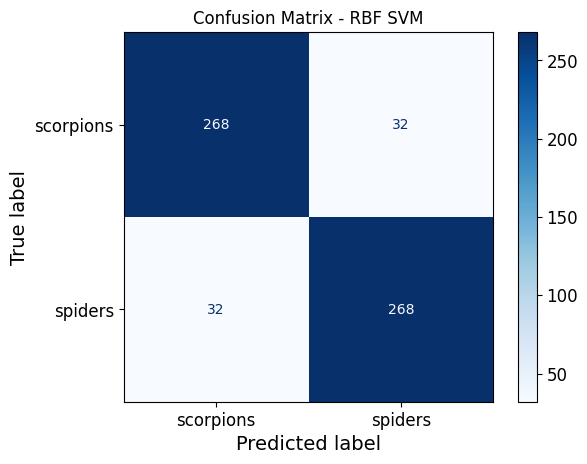

In [ ]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - RBF SVM")
plt.show()


# Plot

In [ ]:
# ลดมิติของ feature ที่ scale แล้วด้วย PCA เหลือ 2 มิติ
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_all_scaled)
X_test_pca  = pca.transform(X_test_scaled)

# เทรน SVM RBF ใน space 2D นี้ เพื่อวาด boundary ให้เห็นในกราฟ
svm_rbf_2d = SVC(kernel="rbf", C=C_value, gamma=gamma_value)
svm_rbf_2d.fit(X_train_pca, y_train_all)


SVC(C=5.0)

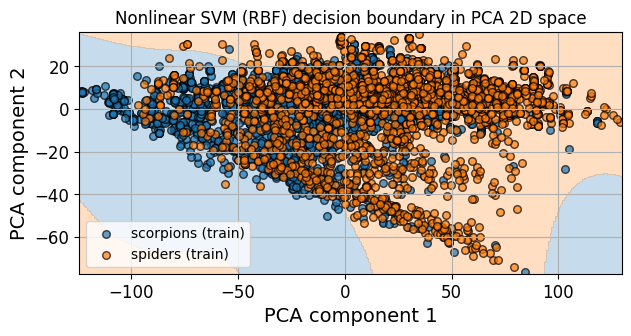

In [ ]:
# วาด decision boundary + จุดข้อมูล
plt.figure(figsize=(7,6))

# สร้าง grid 2D สำหรับวาดเส้น
x_min, x_max = X_train_pca[:,0].min() - 1, X_train_pca[:,0].max() + 1
y_min, y_max = X_train_pca[:,1].min() - 1, X_train_pca[:,1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = svm_rbf_2d.predict(grid_points).reshape(xx.shape)

# พื้นหลัง: โซนของแต่ละคลาสตาม SVM
plt.contourf(xx, yy, Z, alpha=0.25, levels=[-0.5,0.5,1.5], colors=["tab:blue","tab:orange"])

# จุด train
for label_id, cls in enumerate(classes):
    idx = (y_train_all == label_id)
    plt.scatter(
        X_train_pca[idx, 0],
        X_train_pca[idx, 1],
        label=f"{cls} (train)",
        alpha=0.7,
        edgecolor="k",
        s=30
    )

plt.xlabel("PCA component 1")
plt.ylabel("PCA component 2")
plt.title("Nonlinear SVM (RBF) decision boundary in PCA 2D space")
plt.legend()
plt.grid(True)
plt.gca().set_aspect('equal', adjustable='box')  # ให้สเกลแกน x,y เท่ากัน
plt.show()
